In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv.csv')

In [3]:
df.head(5)

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [4]:
df.shape

(2000, 12)

# EDA Process

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   str    
 1   instructor_id               2000 non-null   str    
 2   course_id                   2000 non-null   str    
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), str(3)
memory usage: 216.9 KB


In [6]:
df.isnull().sum()

batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

There are no missing values so no need of imputations 

In [7]:
df.duplicated().sum() # No duplicates also 

np.int64(0)

In [8]:
print('The numbers of Instructors:',df['instructor_id'].nunique()) # the number of Instructors
print('The numbers of courses:',df['course_id'].nunique()) # the number of courses

The numbers of Instructors: 120
The numbers of courses: 25


In [9]:
df.groupby('instructor_id').size().describe()

count    120.000000
mean      16.666667
std        4.582270
min        7.000000
25%       13.750000
50%       17.000000
75%       19.000000
max       31.000000
dtype: float64

This shows how many batches each instructor has taught and gives summary statistics such as the min,max and average number of batches.
here the minimum is 7 and max is 31 batches per instructor

In [10]:
df.describe() # this gives the max value and the ranges 

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


we are obersing that most of the ranges of variables lie btwn 0-1 except score improvement, quiz score, and feedback score are measured on different scales. 
We will scale them further

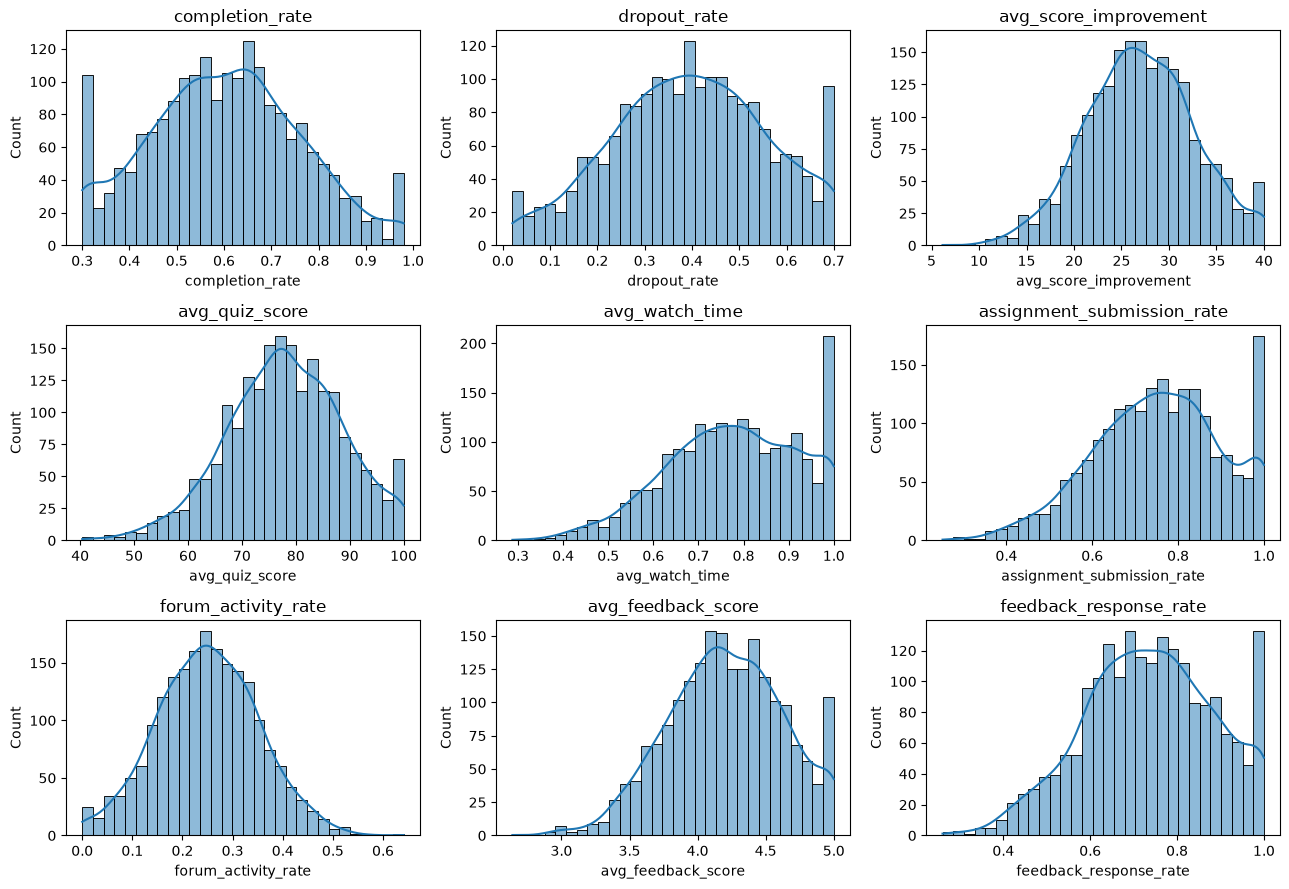

In [11]:
num_cols=['completion_rate',
        'dropout_rate',
        'avg_score_improvement',
        'avg_quiz_score',
        'avg_watch_time',
        'assignment_submission_rate',
        'forum_activity_rate',
        'avg_feedback_score',
        'feedback_response_rate']

fig, axes = plt.subplots(3, 3, figsize=(13, 9))

for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


Here Histograms used to understand the distribution
so we can see some follow normal distribution while features like avg_watch_time is left skewed

<Axes: >

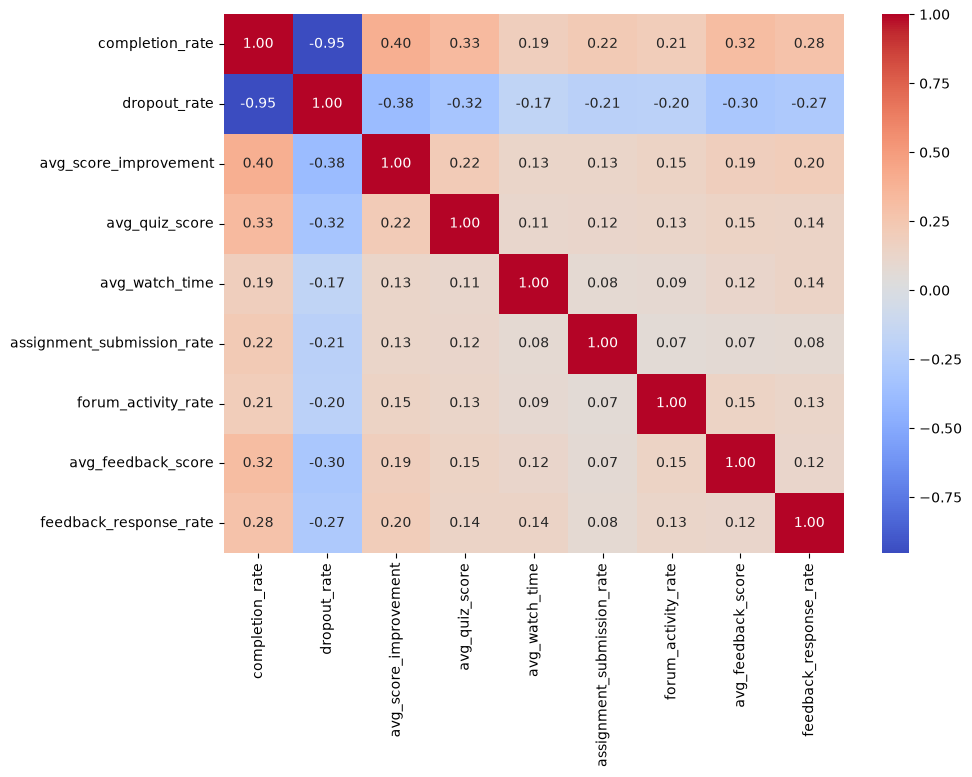

In [12]:
# correlation 
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(),annot=True,fmt=".2f",cmap="coolwarm")


As we can see there is high negative correlation between completion_rate and dropout_rate 
since that means they contain almost same info 
#### we will exclude the dropout in the model building

## Defining the Instructor effectiveness score 

lets define 
##### instructor_effectiveness=(completeion_rate_score+average_score+avg_quiz_score )/3
This will be our outcome metric  to create the effectiveenss tier 


then we can use the engagement and feedback metrics as input too see whther learner behavior and feedback can predict the outcome for effectiveness

### 1. Aggregation to instructor level
aggregating the data to instructor level using the formula we created as base 
calculating the average for typical performance

In [13]:
agg_cols = [
    'completion_rate',
    'avg_score_improvement',
    'avg_quiz_score',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_score',
    'feedback_response_rate'
]
inst = df.groupby('instructor_id')[agg_cols].mean().reset_index()
inst.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,0.543887,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858
1,I_002,0.730874,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338
2,I_003,0.768447,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132
3,I_004,0.458328,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460
4,I_005,0.859747,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197


Since the metric we measured are of different scales normalizing it to the scale of 0 - 1 

In [14]:
inst['improvement_score'] = inst['avg_score_improvement'] / 40
inst['quiz_score'] = inst['avg_quiz_score'] / 100
 # using the max value to divide to get the range 0-1 normalization 

In [17]:
inst['effectiveness_score'] = inst[['completion_rate','improvement_score','quiz_score']].mean(axis=1)


In [18]:
inst[['instructor_id', 'effectiveness_score']].sort_values('effectiveness_score',ascending=False).head()
# highest to lowest top 5 instructors id 

,instructor_id,effectiveness_score
9,I_010,0.906256
36,I_037,0.883573
90,I_091,0.860609
104,I_105,0.857797
17,I_018,0.854543


In [19]:
inst['effectiveness_tier'] = pd.qcut(inst['effectiveness_score'],q=3,labels=['Low', 'Medium', 'High'])
# since there are no fix thresholds we divide it into three groups based on their score 

In [20]:
inst['effectiveness_tier'].value_counts()

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

<Axes: xlabel='effectiveness_tier', ylabel='count'>

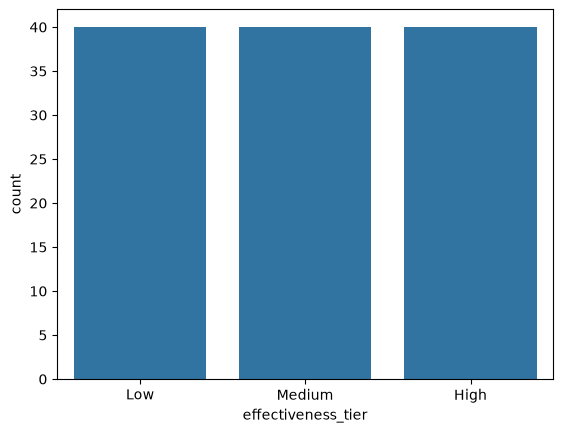

In [21]:
sns.countplot(data=inst,x='effectiveness_tier') # plotting the count of the tier

### Preparing for ML modeling 

In [22]:
inst.head()

,instructor_id,completion_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,improvement_score,quiz_score,outcome_score,effectiveness_score,effectiveness_tier
0,I_001,0.543887,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,0.666037,0.789002,0.666309,0.666309,Medium
1,I_002,0.730874,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,0.754156,0.817372,0.767467,0.767467,High
2,I_003,0.768447,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,0.749445,0.815909,0.777934,0.777934,High
3,I_004,0.458328,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,0.572801,0.776803,0.602644,0.602644,Low
4,I_005,0.859747,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,0.814716,0.858282,0.844248,0.844248,High


In [24]:
feature_cols = ['avg_watch_time','assignment_submission_rate','forum_activity_rate','avg_feedback_score','feedback_response_rate']
# Engagement and feedback features will be used to predict outcome effectiveness

In [25]:
X = inst[feature_cols]
y = inst['effectiveness_tier']

In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

### USING RANDOM FOREST CLASSIFIER FOR THE CLASIFICAtioN MODEL 
it can handle non linaer relationships unlike logistic 

In [27]:
# 1. Creating Base Model
from sklearn.ensemble import RandomForestClassifier

model=RandomForestClassifier(random_state=42)

In [28]:
model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
y_pred= model.predict(X_test)

In [32]:
from sklearn.metrics import classification_report,accuracy_score,f1_score,confusion_matrix
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

        High       0.78      0.88      0.82         8
         Low       0.62      0.62      0.62         8
      Medium       0.43      0.38      0.40         8

    accuracy                           0.62        24
   macro avg       0.61      0.62      0.62        24
weighted avg       0.61      0.62      0.62        24



In [33]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro-F1:", f1_score(y_test, y_pred, average='macro'))

Accuracy: 0.625
Macro-F1: 0.6161764705882353


In [34]:
confusion_matrix(y_test,y_pred)

array([[7, 0, 1],
       [0, 5, 3],
       [2, 3, 3]])

as we can see the base model accuracy is not much 
for high the model has better recall which means it identifies most of it .However tier mediuum has lowest precision recall and f1-score this means model is not being able to distinguish this class


In [35]:
y.value_counts()

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

there is no class imbalance because we used pd.qcut it divides to equal groups

In [36]:
importance = pd.Series(
    model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

importance

feedback_response_rate        0.332200
avg_feedback_score            0.232612
forum_activity_rate           0.175078
assignment_submission_rate    0.139190
avg_watch_time                0.120920
dtype: float64

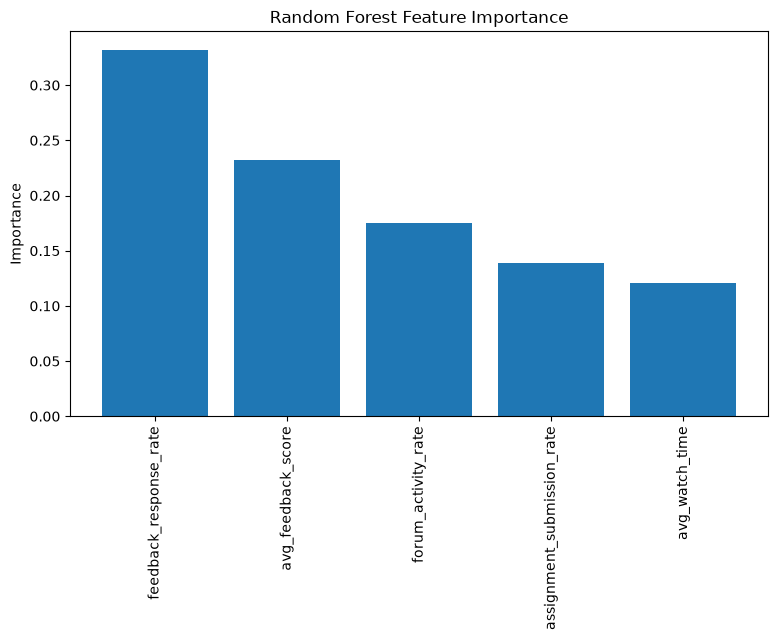

In [53]:
plt.figure(figsize=(9, 5))

plt.bar(importance.index, importance.values)

plt.xticks(rotation=90)
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")

plt.show()

The feature importance shows which engagement and feedback variables were most useful for predicting outcome instructor effectiveness.

feedback_response_rate was the most important feature as per the feature importance from the random forest model followed by avg_feedback_scrore and activity_rate

# Mandatory Analysis Questions


### 1. Which features most influenced instructor effectiveness, and why?
feedback_response_rate was the most important feature as per the feature importance from the random forest model followed by avg_feedback_scrore and activity_rate, this suggest feedback and participation were usefull signals for prediction

### 2. Which variables could be misleading or confounded?
course difficulty can affect the learner outcomes even if the instructor is good.Feedback score also can depend on learner expectations and personal preferences. feeback_response_rate ,may reflect the course design rather than the instructor quality .

### 3. How could this model fail in real-world usage?

The model may not work well for new courses or different types of learners. It may also give misleading results when there is not enough historical data for an instructor.
Medium tier had weak precisiion recall model would struggle at that tier.
The dataset is also fairly small , and GridSearchCV actually made results worse when I tried it,which suggests the model is sensitive to how little data there is

### 4. What additional data would you want to improve this analysis?

I would like to have course difficulty, batch size, learner background, attendance, instructor experience and learner-level performance. This would help separate instructor performance from other factors.

### 5. Should this model be used for instructor performance evaluation? Why or why not?

No, I would not use this model alone to evaluate instructor performance. It can help identify instructors who may need support or training. However, factors like course difficulty and learner background can affect the results, so human review is also needed.

# Limitions of the model built

the effectiveness core is based only on the learner outcome metrics available it doesnt count for factors such as course difficulty or learner background that are not includded therefore  the score may not represent instructor quality perfectly